## <div align="center"> TUGAS LAB IS388 Data Analysis </div>
## <div align="center"> WEEK [05]: [Exploratory Data Analysis]</div>
#### <div align="center"> Semester Ganjil 2024/2025 </div>
---

In [3]:
import datetime
import uuid

studentName = "Joyandro Gerard Diasz"
studentNIM = "00000158474"
studentClass = "B"

In [4]:
myDate = datetime.datetime.now()
myDevice = str(uuid.uuid1())

print("Name: \t\t{}".format(studentName))
print("NIM: \t\t{}".format(studentNIM))
print("NIM: \t\t{}".format(studentClass))
print("Start: \t\t{}".format(myDate))
print("Device ID: \t{}".format(myDevice))

Name: 		Joyandro Gerard Diasz
NIM: 		00000158474
NIM: 		B
Start: 		2026-09-22 14:46:01.821842
Device ID: 	a85d2c1a-b659-11f1-8025-80d54e51d983


---

## <div align="center"> Unguided Lab </div>

### Enter Unguided Lab Code Here:

In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import mannwhitneyu, zscore

sns.set_theme(style="whitegrid")

# Dataset dapat dibuka dari folder Week_05/Unguided atau dari root proyek.
def find_dataset(filename):
    possible_paths = [
        Path(filename),
        Path("Week_05") / "Unguided" / filename,
    ]
    dataset_path = next((path for path in possible_paths if path.is_file()), None)
    if dataset_path is None:
        raise FileNotFoundError(f"{filename} tidak ditemukan.")
    return dataset_path

wine_path = find_dataset("winequality-red.csv")
fuel_path = find_dataset("FuelConsumption.csv")

wine_data = pd.read_csv(wine_path)
fuel_data = pd.read_csv(fuel_path)

print("Dataset wine:", wine_path)
print("Bentuk data wine:", wine_data.shape)
print("Dataset fuel:", fuel_path)
print("Bentuk data fuel:", fuel_data.shape)

Dataset wine: winequality-red.csv
Bentuk data wine: (1599, 12)
Dataset fuel: FuelConsumption.csv
Bentuk data fuel: (1067, 14)


## <div align="center"> Question 01 </div>

In [6]:
# Menghitung matriks korelasi semua variabel numerik.
correlation_matrix = wine_data.corr(numeric_only=True)
quality_correlation = (
    correlation_matrix["quality"]
    .drop("quality")
    .sort_values(ascending=False)
)

print("Korelasi setiap variabel terhadap quality:")
display(quality_correlation.to_frame(name="Correlation"))

highest_positive = quality_correlation.idxmax()
strongest_negative = quality_correlation.idxmin()
weakest_absolute = quality_correlation.abs().idxmin()

print(
    f"Korelasi positif tertinggi: {highest_positive} "
    f"({quality_correlation[highest_positive]:.3f})"
)
print(
    f"Korelasi negatif terkuat: {strongest_negative} "
    f"({quality_correlation[strongest_negative]:.3f})"
)
print(
    f"Hubungan absolut terlemah: {weakest_absolute} "
    f"({quality_correlation[weakest_absolute]:.3f})"
)

Korelasi setiap variabel terhadap quality:


,Correlation
alcohol,0.476166
sulphates,0.251397
citric acid,0.226373
fixed acidity,0.124052
residual sugar,0.013732
free sulfur dioxide,-0.050656
pH,-0.057731
chlorides,-0.128907
density,-0.174919
total sulfur dioxide,-0.185100


Korelasi positif tertinggi: alcohol (0.476)
Korelasi negatif terkuat: volatile acidity (-0.391)
Hubungan absolut terlemah: residual sugar (0.014)


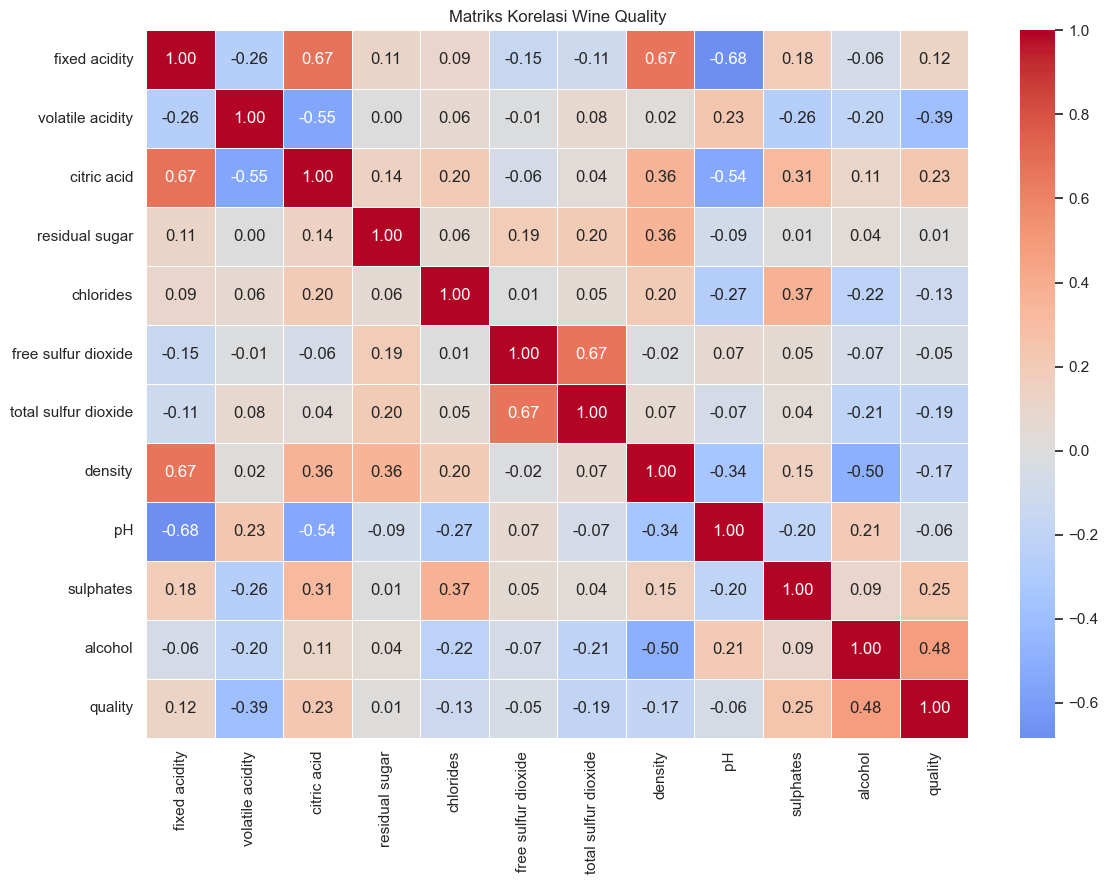

In [7]:
# Memvisualisasikan matriks korelasi agar hubungan antarvariabel mudah diamati.
plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
)
plt.title("Matriks Korelasi Wine Quality")
plt.tight_layout()
plt.show()

## <div align="center"> Question 02 </div>

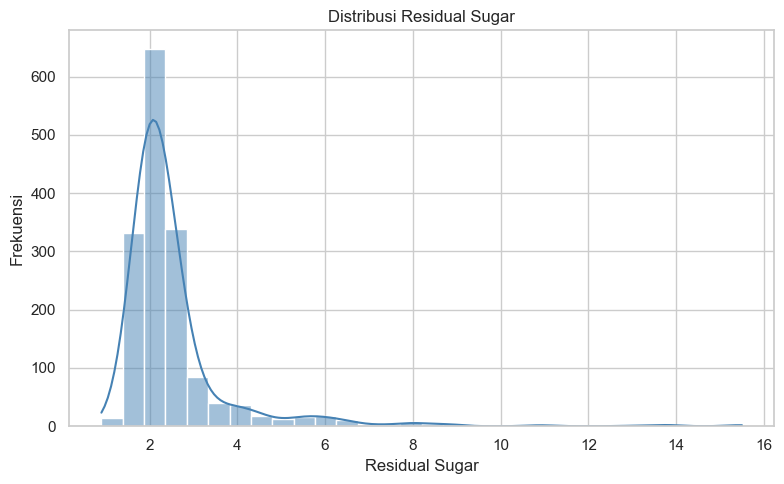

Skewness residual sugar: 4.541
Distribusi condong kuat ke kanan karena nilai skewness positif dan jauh lebih besar dari 1.


In [8]:
# Membuat distribusi residual sugar dan menghitung skewness.
residual_sugar_skewness = wine_data["residual sugar"].skew()

plt.figure(figsize=(8, 5))
sns.histplot(
    data=wine_data,
    x="residual sugar",
    kde=True,
    bins=30,
    color="steelblue",
)
plt.title("Distribusi Residual Sugar")
plt.xlabel("Residual Sugar")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

print(f"Skewness residual sugar: {residual_sugar_skewness:.3f}")
print(
    "Distribusi condong kuat ke kanan karena nilai skewness positif "
    "dan jauh lebih besar dari 1."
)

## <div align="center"> Question 03 </div>

Ringkasan alcohol berdasarkan kategori kualitas:


,count,mean,median,std
quality_category,,,,
Kurang,744,9.926478,9.7,0.758007
Baik,855,10.855029,10.8,1.106109


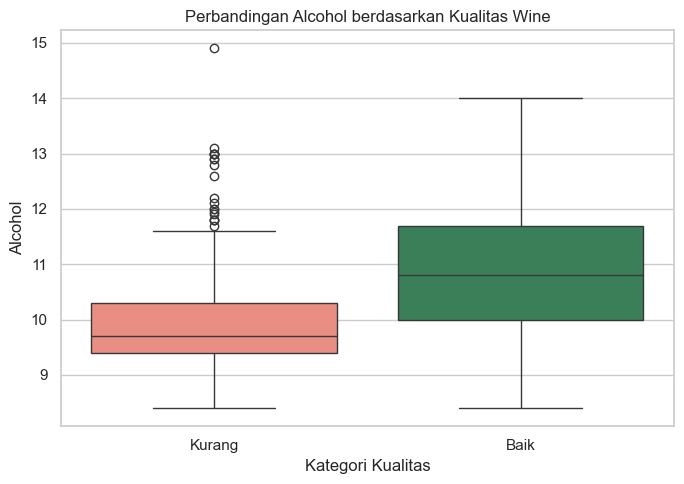

In [9]:
# Membagi kualitas wine menjadi kategori Baik dan Kurang.
wine_data["quality_category"] = np.where(
    wine_data["quality"] >= 6,
    "Baik",
    "Kurang",
)

alcohol_summary = (
    wine_data.groupby("quality_category")["alcohol"]
    .agg(["count", "mean", "median", "std"])
    .reindex(["Kurang", "Baik"])
)

print("Ringkasan alcohol berdasarkan kategori kualitas:")
display(alcohol_summary)

plt.figure(figsize=(7, 5))
sns.boxplot(
    data=wine_data,
    x="quality_category",
    y="alcohol",
    order=["Kurang", "Baik"],
    hue="quality_category",
    palette={"Kurang": "salmon", "Baik": "seagreen"},
    legend=False,
)
plt.title("Perbandingan Alcohol berdasarkan Kualitas Wine")
plt.xlabel("Kategori Kualitas")
plt.ylabel("Alcohol")
plt.tight_layout()
plt.show()

In [10]:
# Uji Mann-Whitney digunakan karena distribusi antargrup tidak diasumsikan normal.
alcohol_good = wine_data.loc[
    wine_data["quality_category"] == "Baik",
    "alcohol",
]
alcohol_poor = wine_data.loc[
    wine_data["quality_category"] == "Kurang",
    "alcohol",
]

mann_whitney_result = mannwhitneyu(
    alcohol_good,
    alcohol_poor,
    alternative="two-sided",
)

print(f"U statistic: {mann_whitney_result.statistic:.0f}")
print(f"P-value: {mann_whitney_result.pvalue:.3e}")
print(
    "Kandungan alcohol kelompok Baik lebih tinggi. "
    "P-value < 0,05 menunjukkan perbedaan yang signifikan secara statistik."
)

U statistic: 481313
P-value: 2.006e-70
Kandungan alcohol kelompok Baik lebih tinggi. P-value < 0,05 menunjukkan perbedaan yang signifikan secara statistik.


## <div align="center"> Question 04 </div>

In [11]:
# Memeriksa dan membersihkan data FuelConsumption.
shape_before_cleaning = fuel_data.shape
missing_before = int(fuel_data.isna().sum().sum())
duplicates_before = int(fuel_data.duplicated().sum())

print("Bentuk data sebelum pembersihan:", shape_before_cleaning)
print("Jumlah missing values:", missing_before)
print("Jumlah baris duplikat:", duplicates_before)

fuel_data_clean = fuel_data.drop_duplicates().copy()
numeric_columns = fuel_data_clean.select_dtypes(include="number").columns
fuel_data_clean[numeric_columns] = fuel_data_clean[numeric_columns].fillna(
    fuel_data_clean[numeric_columns].mean()
)

print("Bentuk data setelah pembersihan:", fuel_data_clean.shape)
print("Missing values setelah pembersihan:", int(fuel_data_clean.isna().sum().sum()))
print("Duplikasi setelah pembersihan:", int(fuel_data_clean.duplicated().sum()))
print("Kolom numerik:", list(numeric_columns))

Bentuk data sebelum pembersihan: (1067, 14)
Jumlah missing values: 0
Jumlah baris duplikat: 0
Bentuk data setelah pembersihan: (1067, 14)
Missing values setelah pembersihan: 0
Duplikasi setelah pembersihan: 0
Kolom numerik: ['Unnamed: 0', 'MODELYEAR', 'ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_CITY', 'FUELCONSUMPTION_HWY', 'FUELCONSUMPTION_COMB', 'FUELCONSUMPTION_COMB_MPG', 'CO2EMISSIONS']


## <div align="center"> Question 05 </div>

In [12]:
# Menampilkan statistik deskriptif untuk semua kolom numerik.
numeric_summary = fuel_data_clean[numeric_columns].describe().T
display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,1067.0,533.000000,308.160672,0.0,266.50,533.0,799.50,1066.0
MODELYEAR,1067.0,2014.000000,0.000000,2014.0,2014.00,2014.0,2014.00,2014.0
ENGINESIZE,1067.0,3.346298,1.415895,1.0,2.00,3.4,4.30,8.4
CYLINDERS,1067.0,5.794752,1.797447,3.0,4.00,6.0,8.00,12.0
FUELCONSUMPTION_CITY,1067.0,13.296532,4.101253,4.6,10.25,12.6,15.55,30.2
FUELCONSUMPTION_HWY,1067.0,9.474602,2.794510,4.9,7.50,8.8,10.85,20.5
FUELCONSUMPTION_COMB,1067.0,11.580881,3.485595,4.7,9.00,10.9,13.35,25.8
FUELCONSUMPTION_COMB_MPG,1067.0,26.441425,7.468702,11.0,21.00,26.0,31.00,60.0
CO2EMISSIONS,1067.0,256.228679,63.372304,108.0,207.00,251.0,294.00,488.0


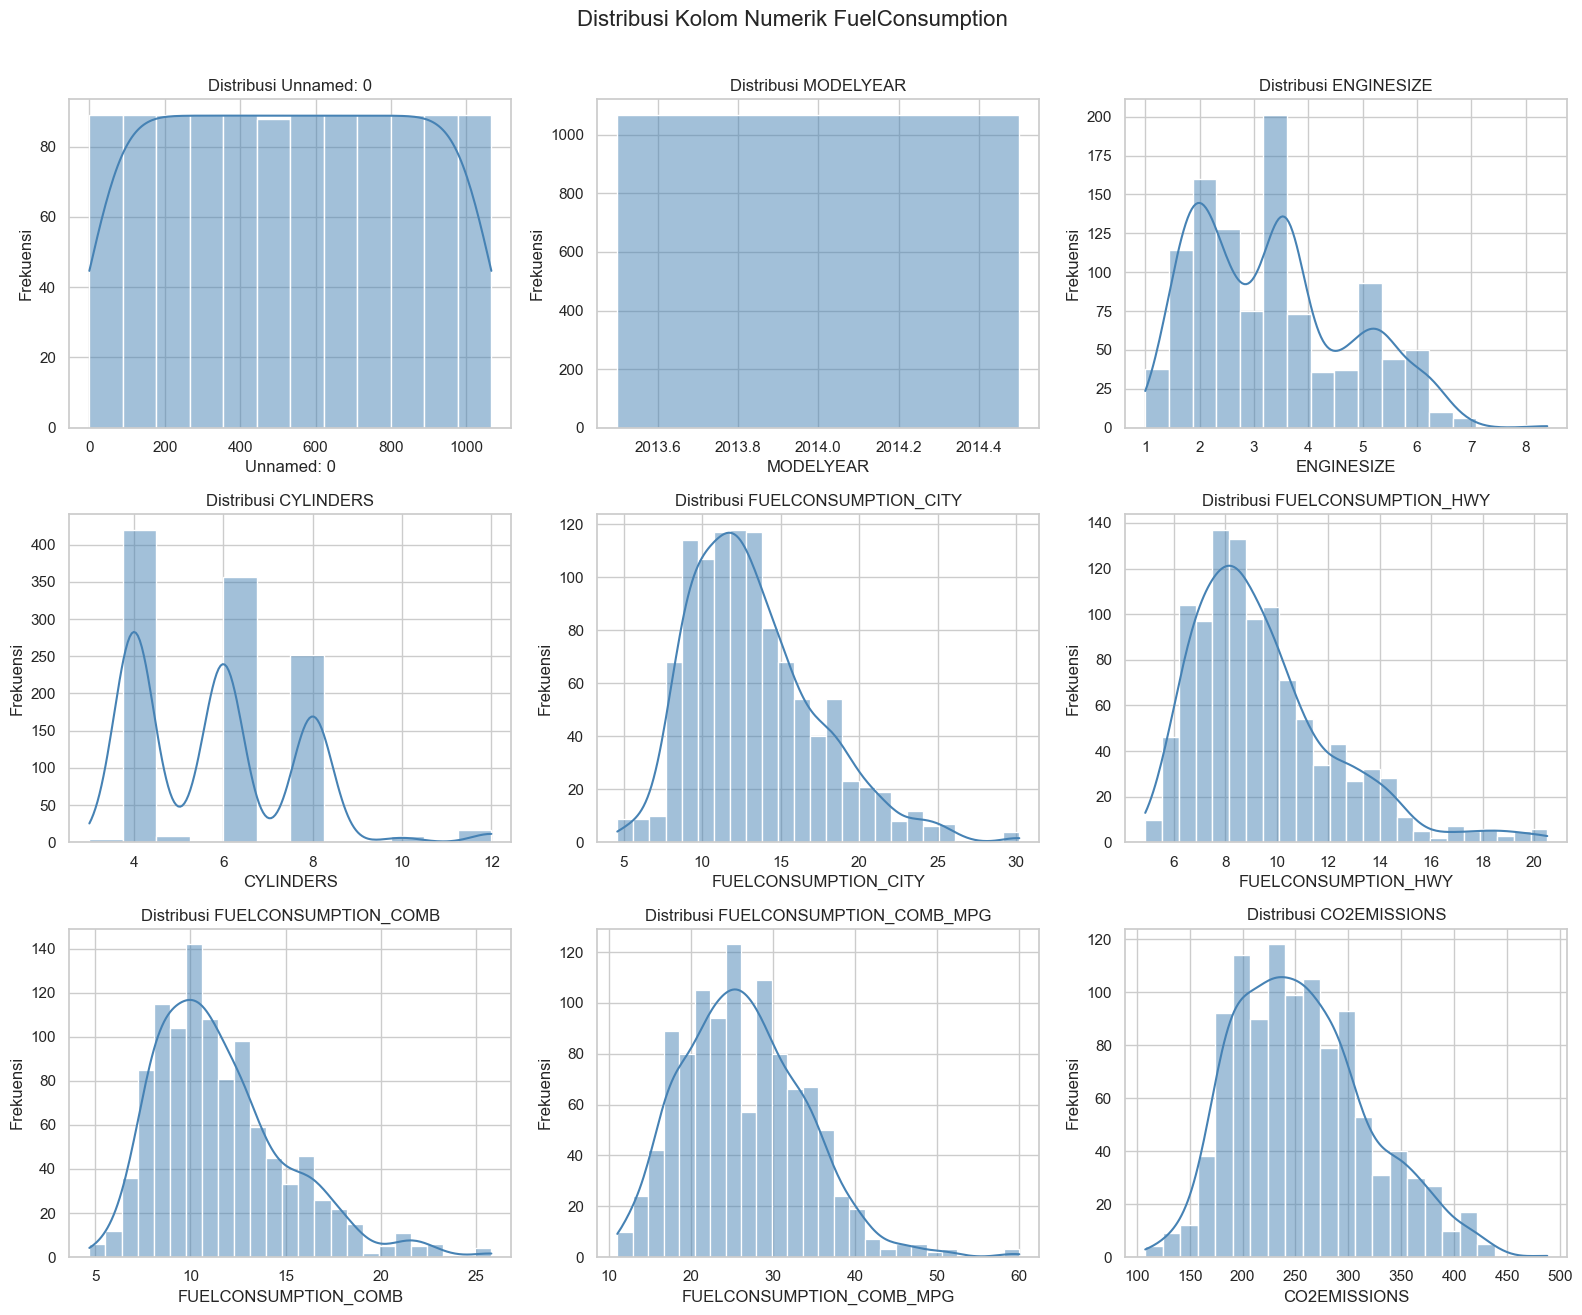

In [13]:
# Membuat histogram dan KDE untuk sembilan kolom numerik.
fig, axes = plt.subplots(3, 3, figsize=(16, 13))
for column, axis in zip(numeric_columns, axes.flat):
    sns.histplot(
        data=fuel_data_clean,
        x=column,
        kde=True,
        ax=axis,
        color="steelblue",
    )
    axis.set_title(f"Distribusi {column}")
    axis.set_ylabel("Frekuensi")

plt.suptitle("Distribusi Kolom Numerik FuelConsumption", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

## <div align="center"> Question 06 </div>

Jumlah outlier CO2EMISSIONS: 1


,MAKE,MODEL,VEHICLECLASS,CO2EMISSIONS,CO2_ZScore
349,FORD,E350 WAGON,VAN - PASSENGER,488,3.659012


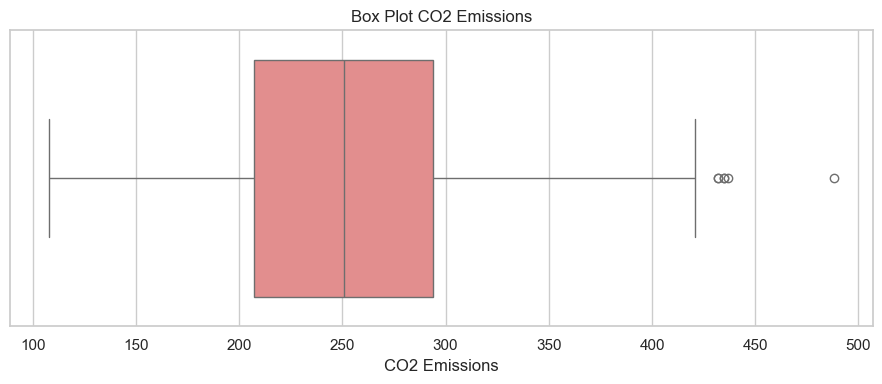

Nilai emisi 488 dari Ford E350 Wagon merupakan data ekstrem, tetapi masih masuk akal untuk kendaraan besar. Nilai ini dapat menaikkan rata-rata dan memengaruhi analisis atau model yang sensitif terhadap outlier.


In [14]:
# Mendeteksi outlier CO2EMISSIONS dengan batas |z-score| > 3.
co2_zscore = zscore(fuel_data_clean["CO2EMISSIONS"])
outlier_mask = np.abs(co2_zscore) > 3
co2_outliers = fuel_data_clean.loc[outlier_mask].copy()
co2_outliers["CO2_ZScore"] = co2_zscore[outlier_mask]

print("Jumlah outlier CO2EMISSIONS:", len(co2_outliers))
display(
    co2_outliers[
        ["MAKE", "MODEL", "VEHICLECLASS", "CO2EMISSIONS", "CO2_ZScore"]
    ]
)

plt.figure(figsize=(9, 4))
sns.boxplot(
    data=fuel_data_clean,
    x="CO2EMISSIONS",
    color="lightcoral",
)
plt.title("Box Plot CO2 Emissions")
plt.xlabel("CO2 Emissions")
plt.tight_layout()
plt.show()

print(
    "Nilai emisi 488 dari Ford E350 Wagon merupakan data ekstrem, "
    "tetapi masih masuk akal untuk kendaraan besar. Nilai ini dapat "
    "menaikkan rata-rata dan memengaruhi analisis atau model yang sensitif "
    "terhadap outlier."
)

----

## <div align="center"> Conclusion </div>

### Kesimpulan

Analisis `winequality-red.csv` menunjukkan bahwa `alcohol` memiliki korelasi positif tertinggi dengan `quality`, sedangkan `volatile acidity` memiliki korelasi negatif terkuat. Distribusi `residual sugar` sangat condong ke kanan. Wine berkategori **Baik** memiliki kandungan alkohol yang lebih tinggi daripada kategori **Kurang**, dan uji Mann-Whitney menunjukkan perbedaan yang signifikan.

Dataset `FuelConsumption.csv` tidak memiliki missing value maupun baris duplikat, sehingga bentuknya tetap 1.067 x 14 setelah pembersihan. Analisis z-score menemukan satu outlier `CO2EMISSIONS`, yaitu Ford E350 Wagon dengan nilai emisi 488.

----

In [15]:
studentName2 = "Nama2"
studentNIM2 = "NIM2"
studentClass2 = "Class2"

In [16]:
print("Name: \t\t{}".format(studentName2))
print("NIM: \t\t{}".format(studentNIM2))
print("NIM: \t\t{}".format(studentClass2))
print("End: \t\t{}".format(myDate))
print("Device ID: \t{}".format(myDevice))

Name: 		Nama2
NIM: 		NIM2
NIM: 		Class2
End: 		2026-09-22 14:46:01.821842
Device ID: 	a85d2c1a-b659-11f1-8025-80d54e51d983


----

## <div align="center"> Reference </div>

### Referensi

- IS388 UNGUIDED WEEK 05 ID.pdf, Soal 1-6.
- winequality-red.csv, dataset praktikum.
- FuelConsumption.csv, dataset praktikum.

----